In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

movies = pd.read_csv("../data/movies_cleaned.csv")

sns.set_theme(style="whitegrid")

print("Dataset loaded successfully!")
print("Total movies:", len(movies))

Matplotlib is building the font cache; this may take a moment.


Dataset loaded successfully!
Total movies: 2503


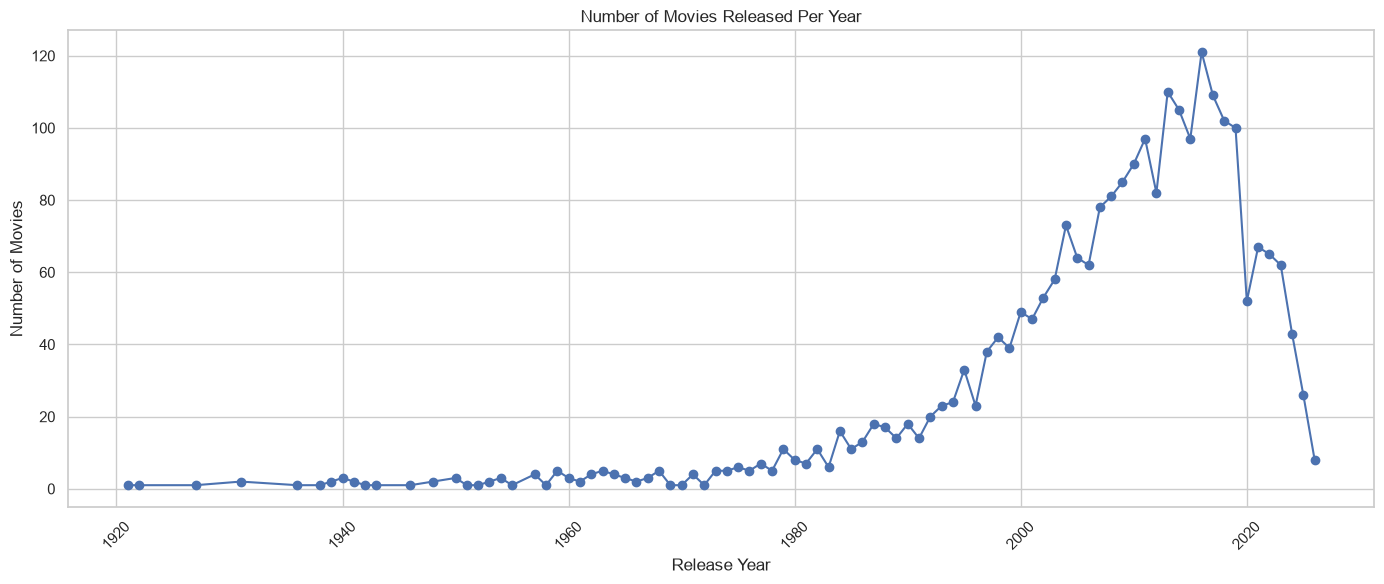

In [2]:
movies["release_year"] = pd.to_datetime(
    movies["release_date"],
    errors="coerce"
).dt.year

yearly_movies = (
    movies.dropna(subset=["release_year"])
    .groupby("release_year")
    .size()
)

plt.figure(figsize=(14, 6))

yearly_movies.plot(kind="line", marker="o")

plt.title("Number of Movies Released Per Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Movies")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

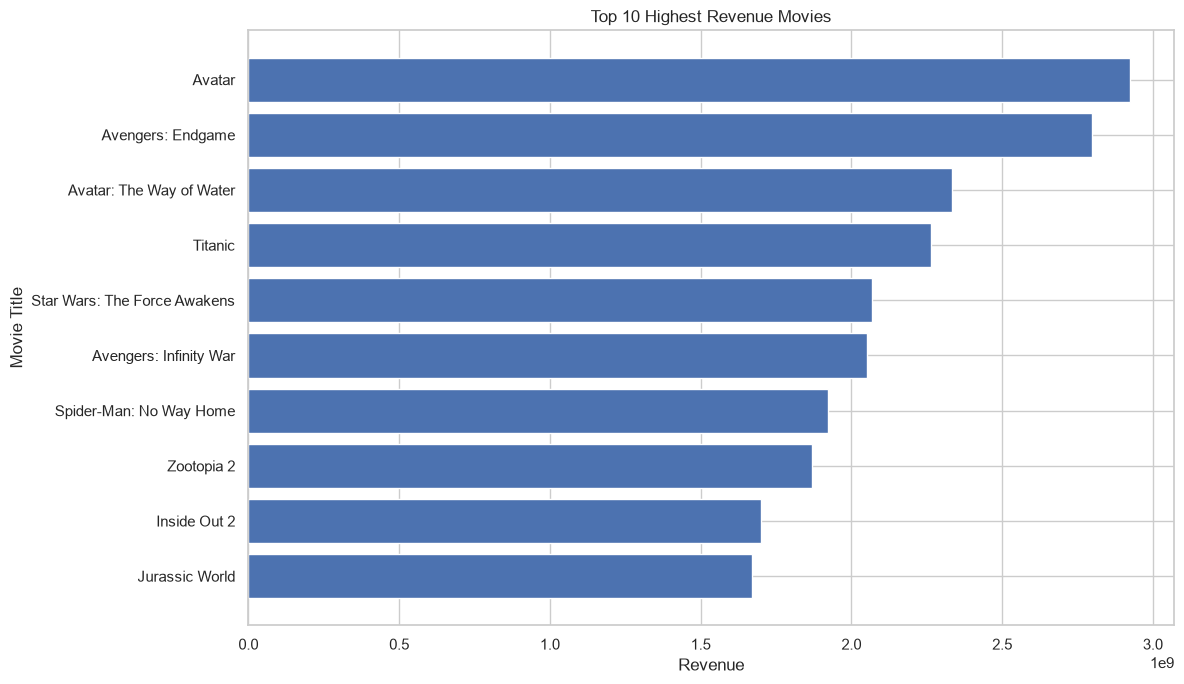

In [3]:
top_revenue = (
    movies[movies["revenue"] > 0]
    .nlargest(10, "revenue")
    .sort_values("revenue")
)

plt.figure(figsize=(12, 7))

plt.barh(top_revenue["title"], top_revenue["revenue"])

plt.title("Top 10 Highest Revenue Movies")
plt.xlabel("Revenue")
plt.ylabel("Movie Title")
plt.tight_layout()
plt.show()

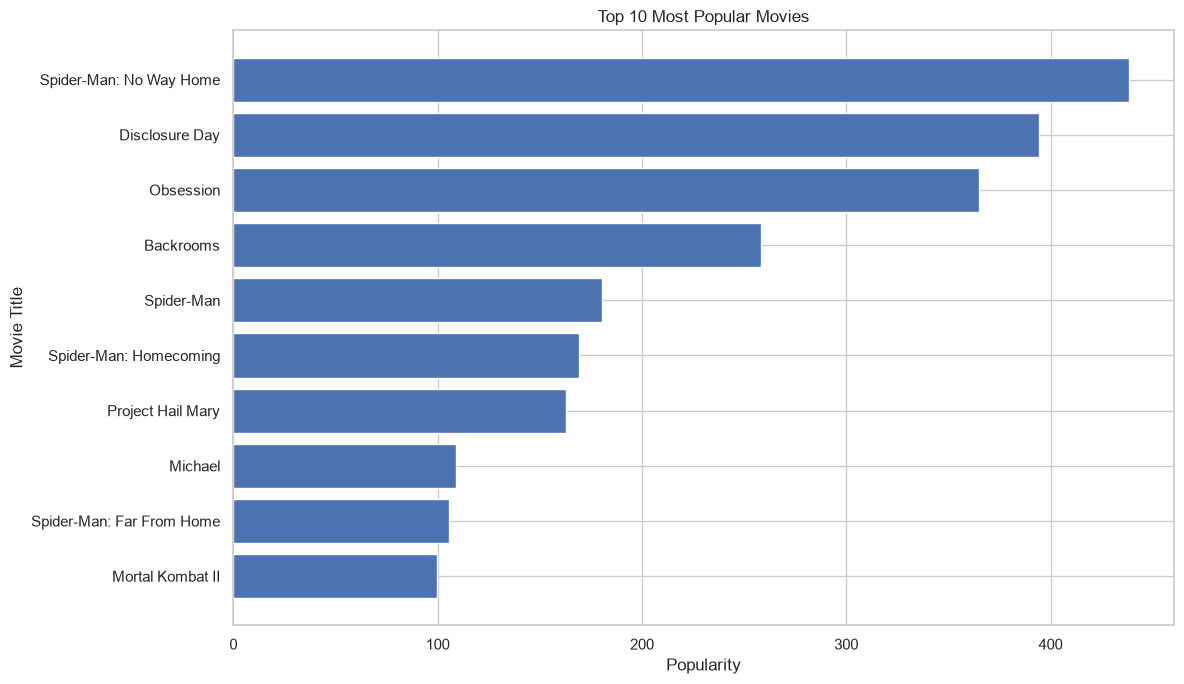

In [4]:
top_popular = (
    movies[movies["popularity"] > 0]
    .nlargest(10, "popularity")
    .sort_values("popularity")
)

plt.figure(figsize=(12, 7))

plt.barh(top_popular["title"], top_popular["popularity"])

plt.title("Top 10 Most Popular Movies")
plt.xlabel("Popularity")
plt.ylabel("Movie Title")
plt.tight_layout()
plt.show()

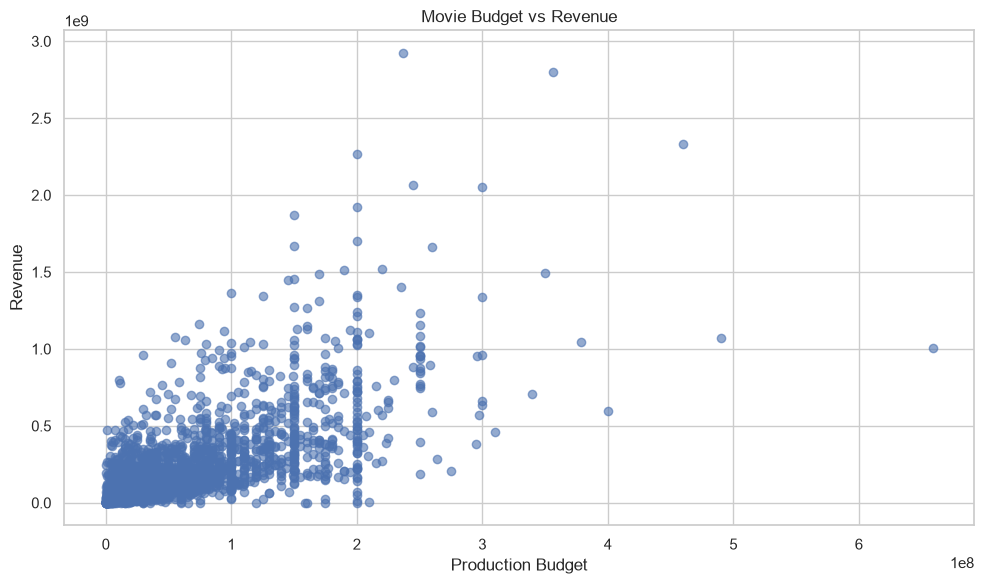

In [5]:
valid_movies = movies[
    (movies["budget"] > 0) &
    (movies["revenue"] > 0)
]

plt.figure(figsize=(10, 6))

plt.scatter(
    valid_movies["budget"],
    valid_movies["revenue"],
    alpha=0.6
)

plt.title("Movie Budget vs Revenue")
plt.xlabel("Production Budget")
plt.ylabel("Revenue")
plt.tight_layout()
plt.show()

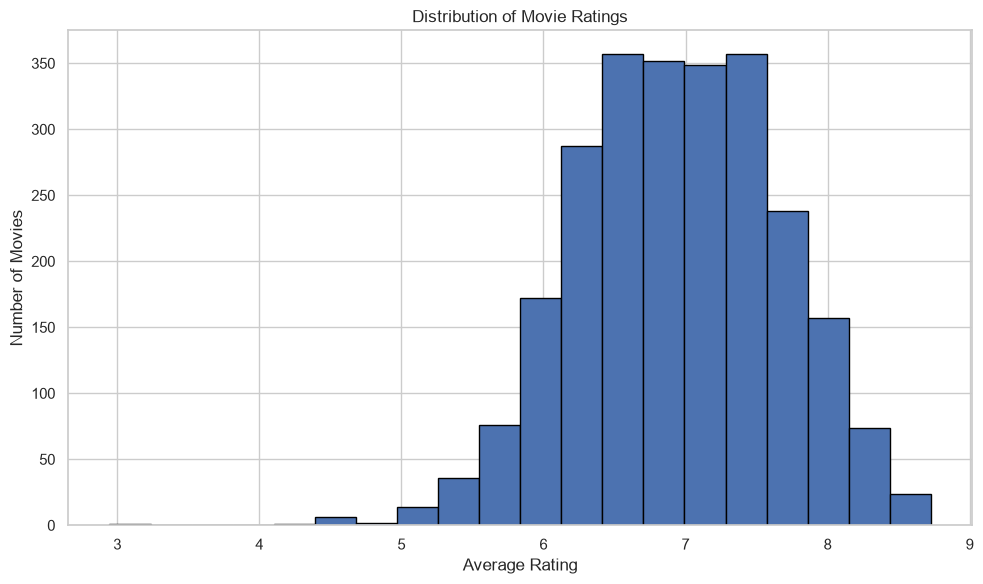

In [6]:
plt.figure(figsize=(10, 6))

plt.hist(
    movies["vote_average"].dropna(),
    bins=20,
    edgecolor="black"
)

plt.title("Distribution of Movie Ratings")
plt.xlabel("Average Rating")
plt.ylabel("Number of Movies")
plt.tight_layout()
plt.show()

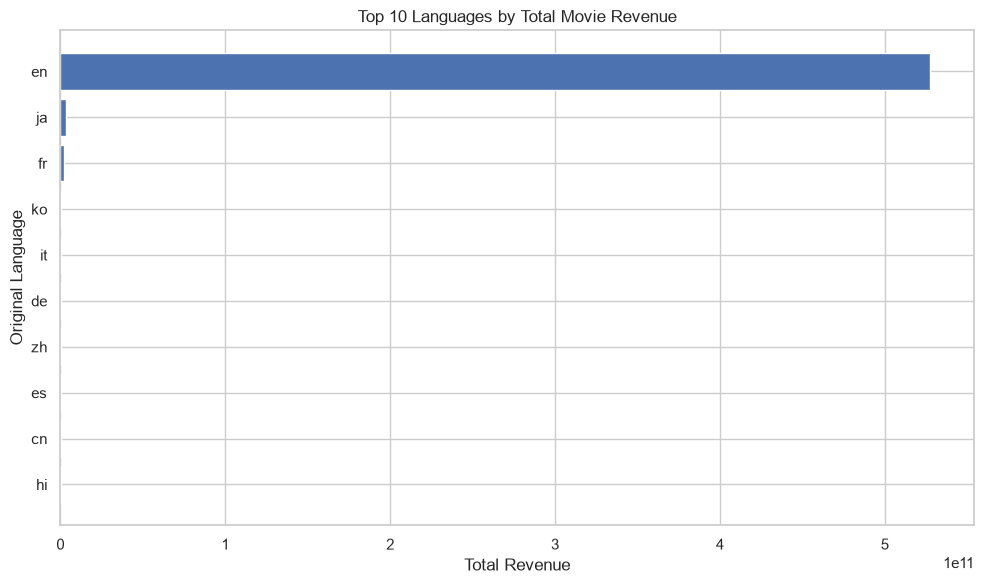

In [7]:
language_revenue = (
    movies[movies["revenue"] > 0]
    .groupby("original_language")["revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .sort_values()
)

plt.figure(figsize=(10, 6))

plt.barh(
    language_revenue.index,
    language_revenue.values
)

plt.title("Top 10 Languages by Total Movie Revenue")
plt.xlabel("Total Revenue")
plt.ylabel("Original Language")
plt.tight_layout()
plt.show()

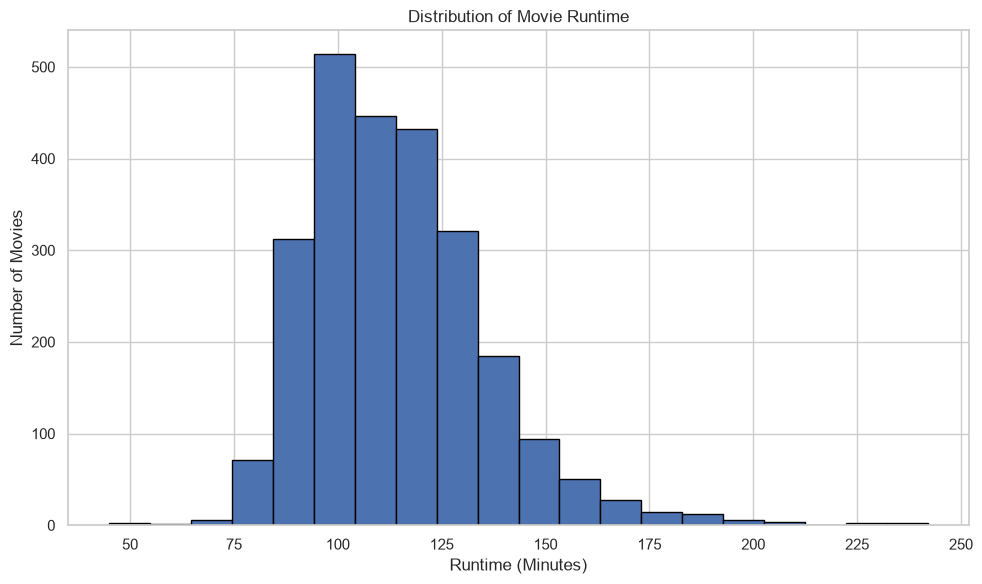

In [8]:
runtime_data = movies[movies["runtime"] > 0]

plt.figure(figsize=(10, 6))

plt.hist(
    runtime_data["runtime"],
    bins=20,
    edgecolor="black"
)

plt.title("Distribution of Movie Runtime")
plt.xlabel("Runtime (Minutes)")
plt.ylabel("Number of Movies")
plt.tight_layout()
plt.show()

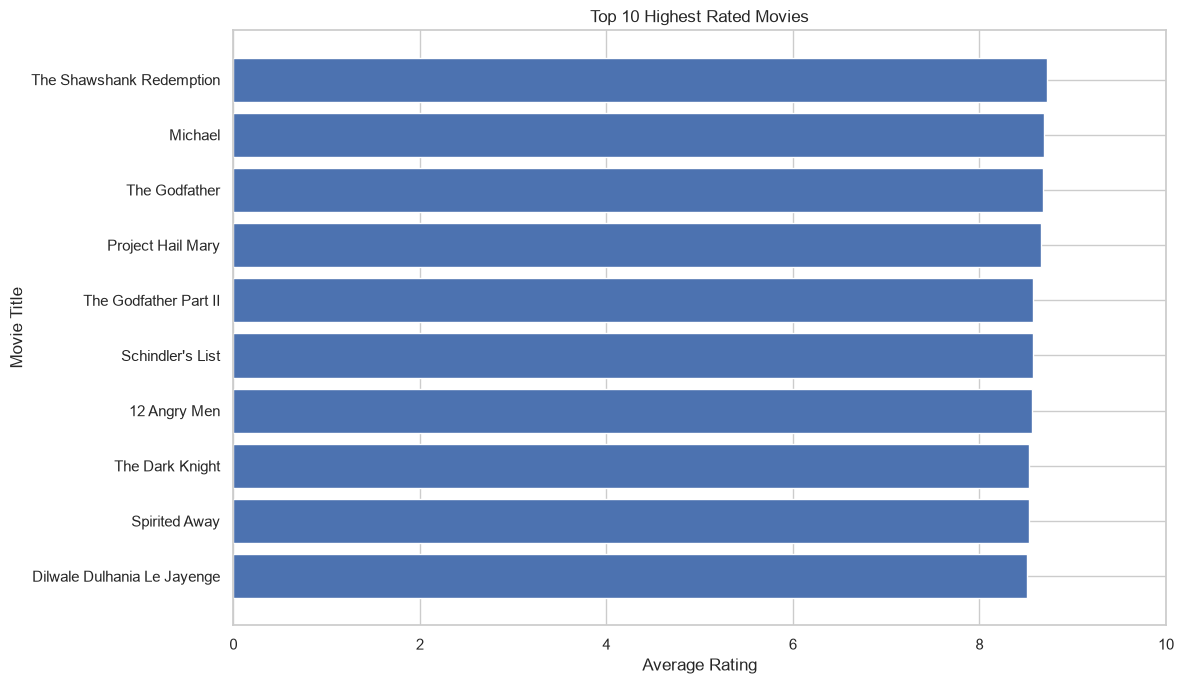

In [9]:
top_rated = (
    movies[movies["vote_count"] >= 100]
    .nlargest(10, "vote_average")
    .sort_values("vote_average")
)

plt.figure(figsize=(12, 7))

plt.barh(
    top_rated["title"],
    top_rated["vote_average"]
)

plt.title("Top 10 Highest Rated Movies")
plt.xlabel("Average Rating")
plt.ylabel("Movie Title")
plt.xlim(0, 10)
plt.tight_layout()
plt.show()

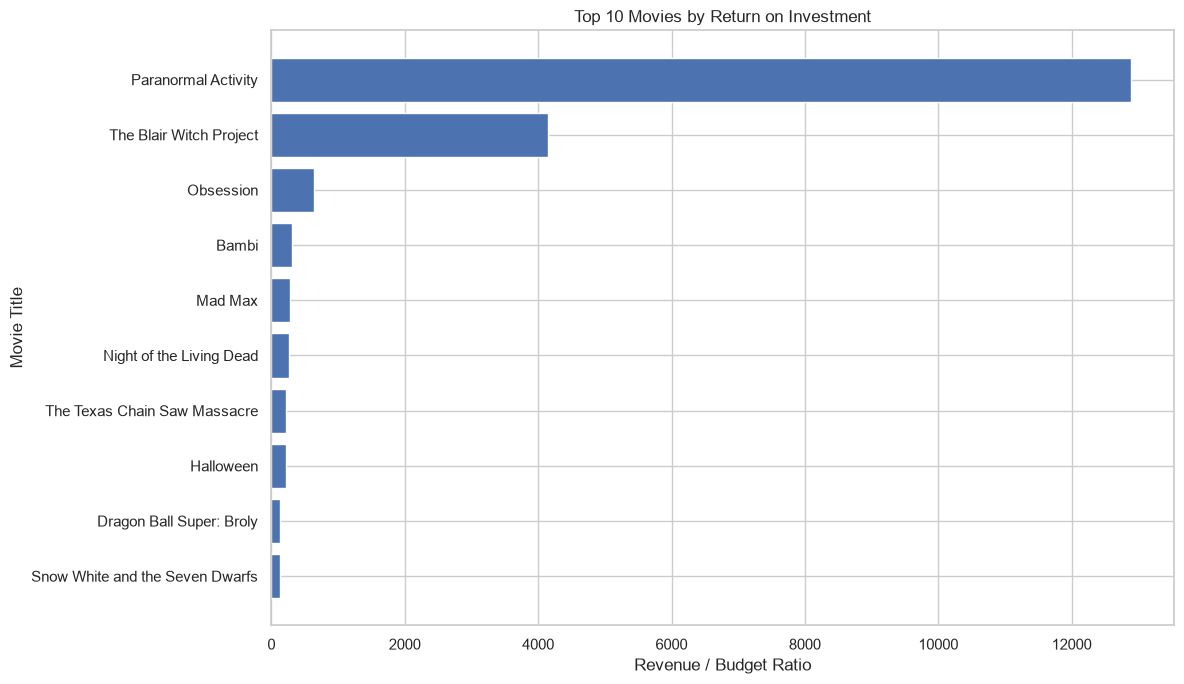

In [10]:
roi_movies = movies[
    (movies["budget"] > 0) &
    (movies["revenue"] > 0)
].copy()

roi_movies["ROI"] = roi_movies["revenue"] / roi_movies["budget"]

top_roi = roi_movies.nlargest(10, "ROI").sort_values("ROI")

plt.figure(figsize=(12, 7))

plt.barh(top_roi["title"], top_roi["ROI"])

plt.title("Top 10 Movies by Return on Investment")
plt.xlabel("Revenue / Budget Ratio")
plt.ylabel("Movie Title")
plt.tight_layout()
plt.show()

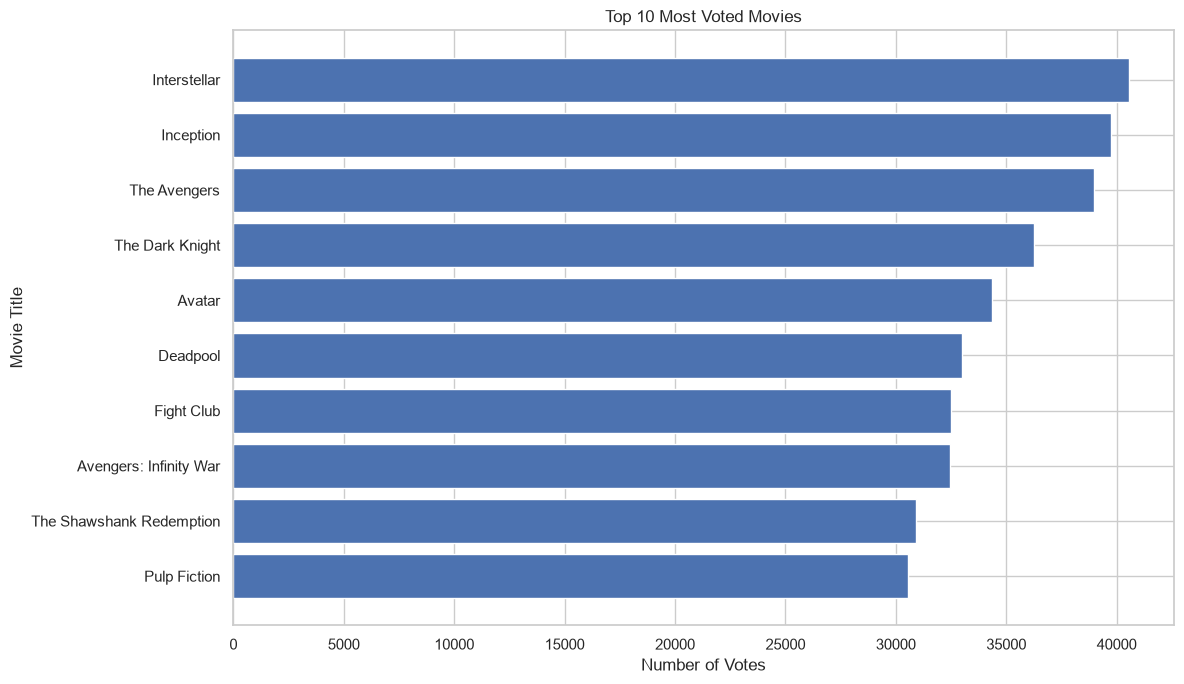

In [11]:
most_voted = (
    movies[movies["vote_count"] > 0]
    .nlargest(10, "vote_count")
    .sort_values("vote_count")
)

plt.figure(figsize=(12, 7))

plt.barh(
    most_voted["title"],
    most_voted["vote_count"]
)

plt.title("Top 10 Most Voted Movies")
plt.xlabel("Number of Votes")
plt.ylabel("Movie Title")
plt.tight_layout()
plt.show()